# Activation Harvesting for SAE Training on UMedPT

Extract, normalize, and save encoder activations from UMedPT's Swin Transformer feature pyramid for training Sparse Autoencoders.

**Supports two data modes:**
1. **SemiCOL** — real H&E colon cancer histopathology (OME-TIFF WSI regions)
2. **Synthetic shapes** — fallback for testing without real data

**Output:** `data/dummy_activations.safetensors`

## 0 · Configuration
Set your paths here — everything else flows from these.

In [1]:
# ========================== EDIT THESE ==========================
DATA_ROOT = None                  # Path to SemiCOL DATASET_TRAIN, or None for synthetic
CHECKPOINT =  "encoder-1.0.4.pt/encoder-1.0.4.pt/encoder.pt"                 # Path to your UMedPT .pt weights, or None for default
PYRAMID_LEVEL = 2                 # Feature pyramid level (2 = Stage 2→3 transition)
N_SAMPLES = 50_000               # Num synthetic images, or max_patches cap for SemiCOL
BATCH_SIZE = 32
IMAGE_SIZE = 224
OUTPUT_PATH = "data/dummy_activations.safetensors"
DEVICE = "cuda:0"                 # "cuda:0" or "cpu"
# ================================================================

In [2]:
import sys, os
from pathlib import Path

sys.path.insert(0, "/home/jovyan/sparse-auto-encoder/UmedPT-sdk")

current = Path(os.getcwd()).absolute()
if current.name == "phase-1":
    project_root = current.parent
elif current.name == "sparse-auto-encoder":
    project_root = current
else:
    project_root = current / "sparse-auto-encoder"

for subdir in ["UmedPT", "UmedPT-sdk"]:
    path = str(project_root / subdir)
    if path not in sys.path:
        sys.path.insert(0, path)
        print(f"Added {path} to sys.path")


## 1 · Imports & Dependencies

In [3]:
import math
import sys
import os
import time
from pathlib import Path
from typing import Optional

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset

from safetensors.torch import save_file, load_file

EPS = 1e-8

os.environ["MMM_LICENSE_ACCEPTED"] = "i accept"
try:
    os.chdir("/home/jovyan/sparse-auto-encoder")
except FileNotFoundError:
    pass

print(f"PyTorch {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

device = torch.device(DEVICE if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

PyTorch 2.10.0+cu128
CUDA available: True
GPU: NVIDIA A100 80GB PCIe
Using device: cuda:0


## 2 · SemiCOL Tissue Classes

The SemiCOL challenge defines 10 tissue classes for colorectal cancer segmentation.
These are the ground-truth concepts we hope the SAE will rediscover as interpretable features.

In [4]:
SEMICOL_CLASSES = {
    0: "BACK",        # Background / glass
    1: "TUMOR",       # Tumor epithelium
    2: "STROMA",      # Tumor stroma
    3: "MUSCLE",      # Muscle
    4: "NECROSIS",    # Necrosis
    5: "MUCUS",       # Mucus / mucin lakes
    6: "NORMAL",      # Normal mucosa
    7: "SUBMUCOSA",   # Submucosa
    8: "ADIPOSE",     # Adipose tissue
    9: "LYMPHOCYTES", # Lymphocytes / inflammatory
}

## 3 · Dataset Classes

### 3a · SemiCOLPatchDataset

Loads SemiCOL OME-TIFF regions and tiles them into 224×224 non-overlapping patches.

```
semicol_root/
    01_MANUAL/         # Manually annotated WSI regions
        images/        # OME-TIFF files (10000×10000 µm regions)
        masks/         # Annotation masks
    02_WEAKLY/         # Weakly labeled (slide-level tumor yes/no)
        TU/            # Tumor-bearing slide regions
        BEN/           # Benign slide regions
```

In [5]:
class SemiCOLPatchDataset(Dataset):
    """
    Loads SemiCOL challenge data (OME-TIFF regions) and extracts
    non-overlapping patches of size (patch_size x patch_size).

    For activation harvesting we use ALL images (annotated + weakly labeled)
    since we only need forward passes, not labels.
    """

    def __init__(
        self,
        root: str,
        patch_size: int = 224,
        max_patches: Optional[int] = None,
        bg_threshold: float = 0.90,
    ):
        self.patch_size = patch_size
        self.bg_threshold = bg_threshold
        self.root = Path(root)
        self.patches = []  # List of (image_path, row, col) tuples

        # ImageNet normalization (standard for UMedPT)
        self.mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        self.std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

        # Discover image files
        image_paths = self._discover_images()
        print(f"[SemiCOL] Found {len(image_paths)} image files")

        # Pre-compute patch grid for each image
        self._build_patch_index(image_paths, max_patches)
        print(f"[SemiCOL] Total patches: {len(self.patches)}")

    def _discover_images(self) -> list:
        paths = []
        extensions = {".tiff", ".tif", ".png", ".jpg", ".jpeg"}
        for ext in extensions:
            paths.extend(self.root.rglob(f"*{ext}"))
            paths.extend(self.root.rglob(f"*{ext.upper()}"))
        # Filter out mask/label files
        paths = [
            p for p in paths
            if "mask" not in p.parent.name.lower()
            and "mask" not in p.name.lower()
            and "label" not in p.name.lower()
        ]
        return sorted(set(paths))

    def _build_patch_index(self, image_paths: list, max_patches: Optional[int]):
        from PIL import Image
        Image.MAX_IMAGE_PIXELS = None  # SemiCOL images can be very large

        for img_path in image_paths:
            try:
                with Image.open(img_path) as img:
                    w, h = img.size
            except Exception as e:
                print(f"  [WARN] Skipping {img_path.name}: {e}")
                continue

            ps = self.patch_size
            for row in range(0, h - ps + 1, ps):
                for col in range(0, w - ps + 1, ps):
                    self.patches.append((str(img_path), row, col))
                    if max_patches and len(self.patches) >= max_patches:
                        return

    def __len__(self) -> int:
        return len(self.patches)

    def __getitem__(self, idx: int):
        from PIL import Image
        import numpy as np

        img_path, row, col = self.patches[idx]
        ps = self.patch_size

        with Image.open(img_path) as img:
            patch = img.crop((col, row, col + ps, row + ps)).convert("RGB")

        arr = np.array(patch, dtype=np.float32) / 255.0
        tensor = torch.from_numpy(arr).permute(2, 0, 1)  # (3, H, W)

        # Background detection: H&E background is typically very bright
        brightness = tensor.mean()
        is_background = brightness > self.bg_threshold

        # Normalize to ImageNet stats
        tensor = (tensor - self.mean) / self.std
        return tensor.float(), int(is_background)

print("✅ SemiCOLPatchDataset defined")

✅ SemiCOLPatchDataset defined


### 3b · SyntheticShapeDataset (Fallback)

Generates geometric shapes (circle, square, triangle, cross) on colored backgrounds.
Each shape is a known ground-truth concept for validating SAE features.

In [6]:
class SyntheticShapeDataset(Dataset):
    SHAPES = ["circle", "square", "triangle", "cross"]

    def __init__(self, n_samples: int = 50_000, image_size: int = 224):
        self.n_samples = n_samples
        self.image_size = image_size

    def __len__(self) -> int:
        return self.n_samples

    def __getitem__(self, idx: int):
        H = W = self.image_size
        shape_idx = idx % len(self.SHAPES)
        shape_name = self.SHAPES[shape_idx]
        g = torch.Generator().manual_seed(idx)

        # Random background color (muted, tissue-like)
        bg_r = torch.rand(1, generator=g).item() * 0.3 + 0.6
        bg_g = torch.rand(1, generator=g).item() * 0.3 + 0.5
        bg_b = torch.rand(1, generator=g).item() * 0.3 + 0.6
        img = torch.full((3, H, W), 0.0)
        img[0], img[1], img[2] = bg_r, bg_g, bg_b

        cx = int(torch.rand(1, generator=g).item() * 0.4 * W + 0.3 * W)
        cy = int(torch.rand(1, generator=g).item() * 0.4 * H + 0.3 * H)
        radius = int(torch.rand(1, generator=g).item() * 0.15 * H + 0.1 * H)

        fg_r = torch.rand(1, generator=g).item() * 0.4
        fg_g = torch.rand(1, generator=g).item() * 0.3
        fg_b = torch.rand(1, generator=g).item() * 0.5

        yy, xx = torch.meshgrid(torch.arange(H), torch.arange(W), indexing="ij")

        if shape_name == "circle":
            mask = ((xx - cx) ** 2 + (yy - cy) ** 2) <= radius ** 2
        elif shape_name == "square":
            mask = ((xx - cx).abs() <= radius) & ((yy - cy).abs() <= radius)
        elif shape_name == "triangle":
            in_base = (yy >= cy) & (yy <= cy + radius)
            frac = (yy - cy).float() / max(radius, 1)
            half_w = (frac * radius).long()
            mask = in_base & ((xx - cx).abs() <= half_w)
        elif shape_name == "cross":
            arm = max(radius // 3, 2)
            vert = ((xx - cx).abs() <= arm) & ((yy - cy).abs() <= radius)
            horiz = ((yy - cy).abs() <= arm) & ((xx - cx).abs() <= radius)
            mask = vert | horiz
        else:
            mask = torch.zeros(H, W, dtype=torch.bool)

        img[0, mask], img[1, mask], img[2, mask] = fg_r, fg_g, fg_b

        # Normalize to ImageNet stats
        mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
        img = (img - mean) / std
        return img.float(), shape_idx


def load_synthetic_dataset(n_samples: int, image_size: int) -> Dataset:
    try:
        from mmm.data_loading.synthetic.shape_dataset import ShapeDataset
        ds = ShapeDataset(n_samples=n_samples, image_size=image_size)
        print(f"[Dataset] Loaded MMM ShapeDataset ({n_samples} samples)")
        return ds
    except (ImportError, Exception) as e:
        print(f"[Dataset] MMM ShapeDataset not available: {e}")

    try:
        from mmm.data_loading.synthetic.artifact import ArtifactDataset
        ds = ArtifactDataset(n_samples=n_samples, image_size=image_size)
        print(f"[Dataset] Loaded MMM ArtifactDataset ({n_samples} samples)")
        return ds
    except (ImportError, Exception) as e:
        print(f"[Dataset] MMM ArtifactDataset not available: {e}")

    print("[Dataset] Using fallback SyntheticShapeDataset")
    return SyntheticShapeDataset(n_samples=n_samples, image_size=image_size)

print("✅ SyntheticShapeDataset & load_synthetic_dataset defined")

✅ SyntheticShapeDataset & load_synthetic_dataset defined


In [7]:
import sys
print([p for p in sys.path if 'UmedPT' in p])

['/home/jovyan/sparse-auto-encoder/UmedPT-sdk', '/home/jovyan/sparse-auto-encoder/UmedPT-sdk', '/home/jovyan/sparse-auto-encoder/UmedPT']


## 4 · Load UMedPT Encoder

Loads the model via MMM's `NativeBlocks` API. If a `.pt` checkpoint is provided,
it overrides the default weights (handles `state_dict`, `model_state_dict`, or raw dict formats).

In [8]:
def load_umedpt(device: str = "cuda:0", checkpoint: Optional[str] = None):
    from mmm.api.M3Model import M3Model, M3_MODELS, DEFAULT_MODEL

    if checkpoint:
        ckpt_path = Path(checkpoint)
        if not ckpt_path.exists():
            raise FileNotFoundError(f"Checkpoint not found: {checkpoint}")
        print(f"[Model] Loading UMedPT from checkpoint: {checkpoint}")

        model = M3Model(M3_MODELS[DEFAULT_MODEL], device_identifier=device)

        state = torch.load(checkpoint, map_location=device, weights_only=False)
        if isinstance(state, dict) and "state_dict" in state:
            state = state["state_dict"]
        elif isinstance(state, dict) and "model_state_dict" in state:
            state = state["model_state_dict"]

        try:
            model.load_state_dict(state, strict=False)
            print("[Model] Loaded checkpoint into full model")
        except Exception:
            try:
                model["encoder"].load_state_dict(state, strict=False)
                print("[Model] Loaded checkpoint into encoder only")
            except Exception as e:
                print(f"[Model] WARNING: partial load — {e}")
    else:
        print("[Model] Loading UMedPT (auto-download default weights)")
        model = M3Model(M3_MODELS[DEFAULT_MODEL], device_identifier=device)

    encoder = model["encoder"]
    encoder.eval()
    print(f"[Model] Encoder ready on {device}")
    return model, encoder

model, encoder = load_umedpt(DEVICE, checkpoint=CHECKPOINT)

/opt/conda/envs/myenv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[Model] Loading UMedPT from checkpoint: encoder-1.0.4.pt/encoder-1.0.4.pt/encoder.pt


/home/jovyan/sparse-auto-encoder/UmedPT/mmm/api/M3Model.py:111: LogfireNotConfiguredWarning: No logs or spans will be created until `logfire.configure()` has been called. Set the environment variable LOGFIRE_IGNORE_NO_CONFIG=1 or add ignore_no_config=true in pyproject.toml to suppress this warning.
  logfire.warning("Did not load {file} due to {e}", file=file, e=e)


[Model] WARNING: partial load — Expected state_dict to be dict-like, got <class 'mmm.mtl_modules.shared_blocks.PyramidEncoder.PyramidEncoder'>.
[Model] Encoder ready on cuda:0


## 5 · Probe Feature Pyramid

Run a dummy forward pass to discover the shape of each pyramid level.
This tells us `d_model` (channels) and the spatial resolution at each stage.

**Swin hierarchy:** each successive level doubles channels, halves spatial resolution.

In [9]:
def probe_pyramid(encoder, device, image_size=224):
    with torch.inference_mode():
        dummy = torch.rand(1, 3, image_size, image_size, device=device)
        pyramid = encoder(dummy)

    print(f"Feature pyramid: {len(pyramid)} levels\n")
    print(f"{'Level':<8} {'Shape':<25} {'C (d_model)':<15} {'Spatial':<15} {'Tokens/img'}")
    print("-" * 75)
    for i, feat in enumerate(pyramid):
        B, C, H, W = feat.shape
        marker = " ◄── selected" if i == PYRAMID_LEVEL else ""
        print(f"  {i:<6} ({B}, {C:>4}, {H:>3}, {W:>3})     {C:<15} {H}×{W:<12} {H*W}{marker}")
    return pyramid

pyramid = probe_pyramid(encoder, device, IMAGE_SIZE)

# Extract dimensions for selected level
target = pyramid[PYRAMID_LEVEL]
d_model = target.shape[1]
spatial_h, spatial_w = target.shape[2], target.shape[3]
print(f"\nSelected level {PYRAMID_LEVEL}: d_model={d_model}, spatial={spatial_h}×{spatial_w}")

Feature pyramid: 5 levels

Level    Shape                     C (d_model)     Spatial         Tokens/img
---------------------------------------------------------------------------
  0      (1,    3, 224, 224)     3               224×224          50176
  1      (1,  128,  56,  56)     128             56×56           3136
  2      (1,  256,  28,  28)     256             28×28           784 ◄── selected
  3      (1,  512,  14,  14)     512             14×14           196
  4      (1, 1024,   7,   7)     1024            7×7            49

Selected level 2: d_model=256, spatial=28×28


## 6 · Load Dataset

In [10]:
if DATA_ROOT:
    data_root = Path(DATA_ROOT)
    assert data_root.exists(), f"DATA_ROOT does not exist: {data_root}"
    print(f"Loading SemiCOL data from: {data_root}")
    dataset = SemiCOLPatchDataset(
        root=str(data_root),
        patch_size=IMAGE_SIZE,
        max_patches=N_SAMPLES,
    )
    data_source = "semicol"
else:
    print("No DATA_ROOT set → using synthetic data")
    dataset = load_synthetic_dataset(N_SAMPLES, IMAGE_SIZE)
    data_source = "synthetic"

n_images = len(dataset)

dataloader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,   # Avoids shm bus errors in Docker/Nomad
    pin_memory=(device.type == "cuda"),
)

# ── N_effective calculation ──
n_effective_expected = n_images * spatial_h * spatial_w
est_size_gb = n_effective_expected * d_model * 4 / 1e9

print(f"\n{'─' * 50}")
print(f"  Data source:    {data_source}")
print(f"  Patches/images: {n_images:,}")
print(f"  Spatial tokens: {spatial_h}×{spatial_w} = {spatial_h * spatial_w} per image")
print(f"  N_effective:    {n_effective_expected:,} activation vectors")
print(f"  d_model:        {d_model}")
print(f"  Est. size:      {est_size_gb:.2f} GB (float32)")
print(f"{'─' * 50}")

if est_size_gb > 20:
    print(f"\n⚠️  Large tensor ({est_size_gb:.1f} GB)! Consider reducing N_SAMPLES.")

No DATA_ROOT set → using synthetic data
[Dataset] MMM ShapeDataset not available: ShapeDataset.__init__() got an unexpected keyword argument 'n_samples'


<frozen importlib._bootstrap_external>:1241: FutureWarning: The cuda.cudart module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.runtime module instead.


[Dataset] MMM ArtifactDataset not available: cannot import name 'ArtifactDataset' from 'mmm.data_loading.synthetic.artifact' (/home/jovyan/sparse-auto-encoder/UmedPT/mmm/data_loading/synthetic/artifact.py)
[Dataset] Using fallback SyntheticShapeDataset

──────────────────────────────────────────────────
  Data source:    synthetic
  Patches/images: 50,000
  Spatial tokens: 28×28 = 784 per image
  N_effective:    39,200,000 activation vectors
  d_model:        256
  Est. size:      40.14 GB (float32)
──────────────────────────────────────────────────

⚠️  Large tensor (40.1 GB)! Consider reducing N_SAMPLES.


## 7 · Preview Sample Patches

Quick visual sanity check — are we loading real tissue / shapes?

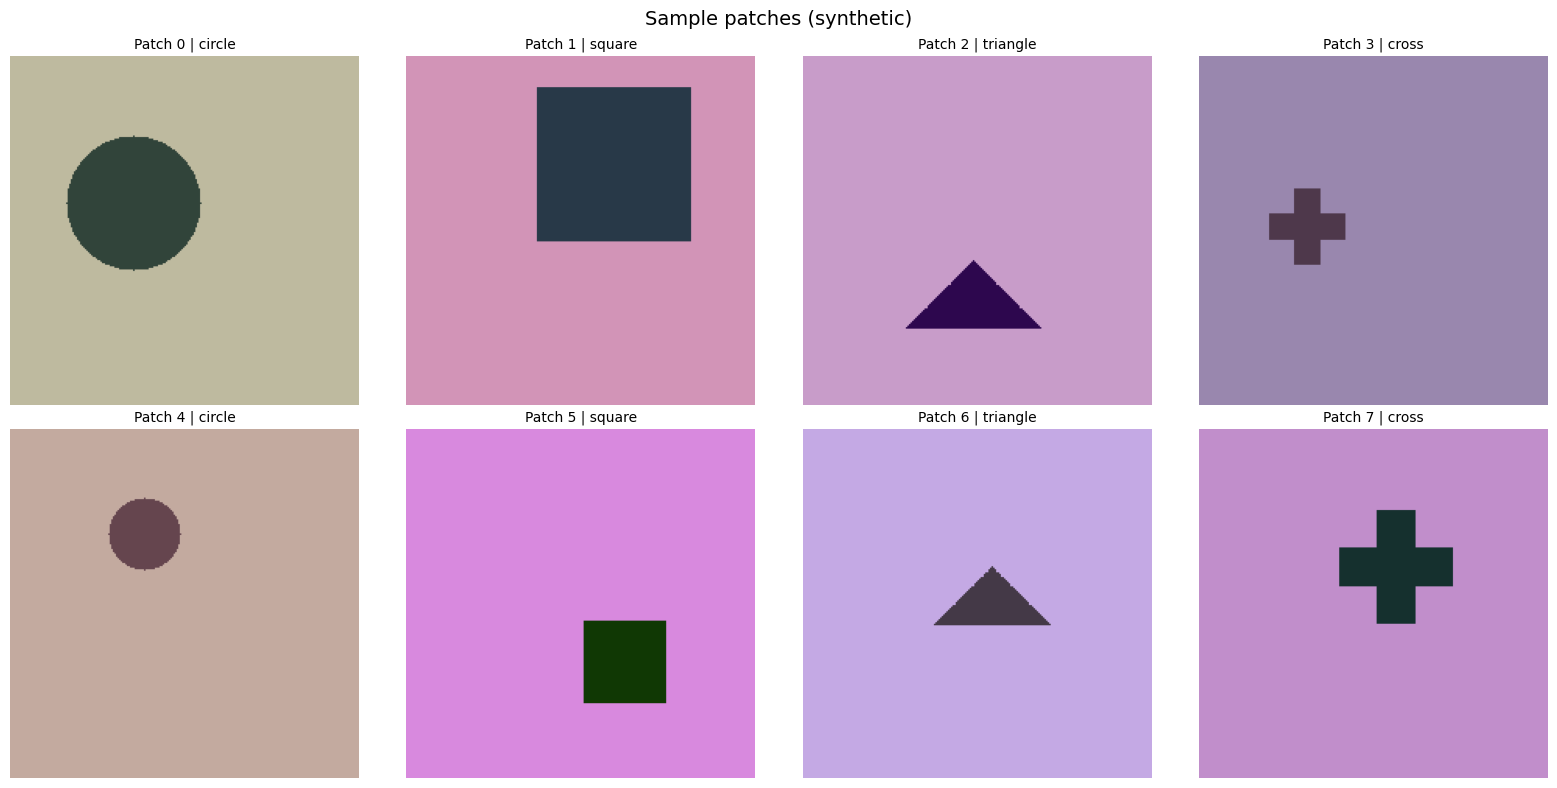

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
mean_t = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std_t = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

for i, ax in enumerate(axes.flat):
    if i >= len(dataset):
        ax.axis("off")
        continue
    img, label = dataset[i]
    # Denormalize for display
    img_vis = (img * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()
    ax.imshow(img_vis)
    if data_source == "semicol":
        ax.set_title(f"Patch {i} | bg={bool(label)}", fontsize=10)
    else:
        shapes = ["circle", "square", "triangle", "cross"]
        ax.set_title(f"Patch {i} | {shapes[label]}", fontsize=10)
    ax.axis("off")

plt.suptitle(f"Sample patches ({data_source})", fontsize=14)
plt.tight_layout()
plt.show()

## 8 · Normalization Function

Anthropic-style scalar normalization: scale each activation vector so the
**average squared L₂ norm = d_model**.

$$\mathbf{x}_{\text{norm}} = \frac{\mathbf{x}}{\text{RMS}(\mathbf{x}) + \epsilon} \cdot \sqrt{d_{\text{model}}}$$

This ensures the SAE training is insensitive to absolute activation scales
across different Swin stages.

In [12]:
def normalize_activations(x: torch.Tensor, d_model: int) -> torch.Tensor:
    """Scale x so avg squared L2 norm = d_model. Shape: (N, D)."""
    rms = x.pow(2).mean(dim=-1, keepdim=True).sqrt() + EPS
    return x / rms * math.sqrt(d_model)

print("✅ normalize_activations defined")

✅ normalize_activations defined


## 9 · Harvest Activations

The main loop:
1. Forward pass each batch through the encoder
2. Extract feature map at the selected pyramid level: `(B, C, H, W)`
3. Flatten spatial dimensions: `(B, C, H, W) → (B·H·W, C)`
4. Collect all vectors, then normalize the full tensor

In [13]:
def harvest_activations(encoder, dataloader, pyramid_level, device):
    encoder.eval()
    all_acts = []

    print(f"Collecting activations from pyramid level {pyramid_level}...")
    t0 = time.time()

    with torch.inference_mode():
        for batch_idx, (images, _labels) in enumerate(dataloader):
            images = images.to(device)
            pyramid = encoder(images)
            feat = pyramid[pyramid_level]  # (B, C, H, W)
            B, C, H, W = feat.shape

            # Flatten: (B, C, H, W) → (B*H*W, C)
            flat = feat.permute(0, 2, 3, 1).reshape(B * H * W, C)
            all_acts.append(flat.cpu())

            if (batch_idx + 1) % 50 == 0:
                n = sum(a.shape[0] for a in all_acts)
                print(f"  Batch {batch_idx + 1:>5} | {n:>12,} vectors | {time.time() - t0:.1f}s")

    activations = torch.cat(all_acts, dim=0).float()
    del all_acts
    elapsed = time.time() - t0

    d = activations.shape[1]
    n = activations.shape[0]
    print(f"\nHarvested {n:,} vectors (d={d}) in {elapsed:.1f}s")

    # Normalize
    avg_sq_before = activations.pow(2).sum(dim=-1).mean().item()
    activations = normalize_activations(activations, d)
    avg_sq_after = activations.pow(2).sum(dim=-1).mean().item()
    print(f"Normalization: avg ‖x‖² = {avg_sq_before:.1f} → {avg_sq_after:.1f} (target: {d})")

    return activations

activations = harvest_activations(encoder, dataloader, PYRAMID_LEVEL, device)
print(f"\nFinal shape: {activations.shape}")
print(f"N_effective = {activations.shape[0]:,}")

  Batch    50 |    1,254,400 vectors | 9.1s
  Batch   100 |    2,508,800 vectors | 18.3s
  Batch   150 |    3,763,200 vectors | 27.4s
  Batch   200 |    5,017,600 vectors | 34.5s
  Batch   250 |    6,272,000 vectors | 43.0s
  Batch   300 |    7,526,400 vectors | 54.0s
  Batch   350 |    8,780,800 vectors | 64.6s
  Batch   400 |   10,035,200 vectors | 75.4s
  Batch   450 |   11,289,600 vectors | 83.9s
  Batch   500 |   12,544,000 vectors | 93.3s
  Batch   550 |   13,798,400 vectors | 101.9s
  Batch   600 |   15,052,800 vectors | 113.5s
  Batch   650 |   16,307,200 vectors | 123.3s
  Batch   700 |   17,561,600 vectors | 134.1s
  Batch   750 |   18,816,000 vectors | 144.9s
  Batch   800 |   20,070,400 vectors | 156.8s
  Batch   850 |   21,324,800 vectors | 166.9s
  Batch   900 |   22,579,200 vectors | 177.9s
  Batch   950 |   23,833,600 vectors | 189.0s
  Batch  1000 |   25,088,000 vectors | 200.1s
  Batch  1050 |   26,342,400 vectors | 211.0s
  Batch  1100 |   27,596,800 vectors | 222.0s

: 

: 

: 

## 10 · Activation Statistics

Quick diagnostics before saving — check the distribution looks healthy.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Distribution of activation values (sample)
sample = activations[:10000].flatten().numpy()
axes[0].hist(sample, bins=100, color="steelblue", alpha=0.8, edgecolor="none")
axes[0].set_title("Activation Value Distribution (sample)")
axes[0].set_xlabel("Value")
axes[0].set_ylabel("Count")

# 2. Per-vector L2 norms
norms = activations.pow(2).sum(dim=-1).sqrt().numpy()
axes[1].hist(norms, bins=100, color="coral", alpha=0.8, edgecolor="none")
axes[1].axvline(math.sqrt(d_model), color="black", linestyle="--",
                label=f"√d_model = {math.sqrt(d_model):.1f}")
axes[1].set_title("Per-Vector L₂ Norms (post-normalization)")
axes[1].set_xlabel("‖x‖₂")
axes[1].legend()

# 3. Per-dimension mean/std
dim_means = activations.mean(dim=0).numpy()
dim_stds = activations.std(dim=0).numpy()
axes[2].plot(dim_means, label="mean", alpha=0.7)
axes[2].fill_between(range(d_model), dim_means - dim_stds, dim_means + dim_stds,
                     alpha=0.2, label="±1 std")
axes[2].set_title(f"Per-Dimension Statistics (d={d_model})")
axes[2].set_xlabel("Dimension")
axes[2].legend()

plt.suptitle(f"Activation Diagnostics — {activations.shape[0]:,} vectors, d={d_model}", fontsize=13)
plt.tight_layout()
plt.show()

print(f"Global mean: {activations.mean().item():.4f}")
print(f"Global std:  {activations.std().item():.4f}")
print(f"Min:         {activations.min().item():.4f}")
print(f"Max:         {activations.max().item():.4f}")

## 11 · Save to Disk

In [ ]:
out_path = Path(OUTPUT_PATH)
out_path.parent.mkdir(parents=True, exist_ok=True)

metadata = {
    "data_source": data_source,
    "pyramid_level": str(PYRAMID_LEVEL),
    "d_model": str(d_model),
    "spatial_h": str(spatial_h),
    "spatial_w": str(spatial_w),
    "n_images": str(n_images),
    "n_effective": str(activations.shape[0]),
    "image_size": str(IMAGE_SIZE),
    "checkpoint": str(CHECKPOINT or "default"),
}

save_file({"activations": activations}, str(out_path), metadata=metadata)

size_mb = out_path.stat().st_size / 1e6
print(f"Saved to: {out_path}")
print(f"  Shape: {tuple(activations.shape)}")
print(f"  Size:  {size_mb:.1f} MB")
print(f"  Metadata: {metadata}")
print(f"\n✅ Bilal can now load this for SAE training:")
print(f'   from safetensors.torch import load_file')
print(f'   data = load_file("{OUTPUT_PATH}")')
print(f'   acts = data["activations"]  # shape: {tuple(activations.shape)}')

## 12 · Verify Saved File

In [ ]:
from safetensors import safe_open

with safe_open(OUTPUT_PATH, framework="pt") as f:
    meta = f.metadata()
    loaded = f.get_tensor("activations")

print(f"Loaded shape: {loaded.shape}")
print(f"Metadata: {meta}")
print(f"Values match: {torch.allclose(activations, loaded)}")
print(f"\n✅ Round-trip verification passed!")

## 13 · Self-Tests

Run these to verify all components work correctly — no GPU or model needed.

In [ ]:
def run_tests():
    n_passed = 0
    n_failed = 0

    def check(name, condition, detail=""):
        nonlocal n_passed, n_failed
        if condition:
            print(f"  ✅ {name}")
            n_passed += 1
        else:
            print(f"  ❌ {name}: {detail}")
            n_failed += 1

    # Test 1: Normalization
    print("\n[Test] Normalization")
    d = 384
    x = torch.randn(1000, d) * 5.0
    x_n = normalize_activations(x, d)
    avg = x_n.pow(2).sum(dim=-1).mean().item()
    check("Avg squared L2 norm ≈ d_model", abs(avg - d) / d < 0.05, f"got {avg:.2f}")
    check("Shape preserved", x_n.shape == x.shape)
    check("No NaN/Inf", not (torch.isnan(x_n).any() or torch.isinf(x_n).any()))

    # Zero vector safety
    x_zero = torch.zeros(1, d)
    check("Zero vector → no NaN", not torch.isnan(normalize_activations(x_zero, d)).any())

    # Test 2: Per-vector normalization
    print("\n[Test] Per-vector normalization")
    x_v = torch.randn(100, d)
    x_v[0] *= 100
    x_v[1] *= 0.001
    norms_sq = normalize_activations(x_v, d).pow(2).sum(dim=-1)
    check("All vectors similar norms", norms_sq.std().item() / norms_sq.mean().item() < 0.01)

    # Test 3: Flattening
    print("\n[Test] Spatial flattening")
    B, C, H, W = 4, 192, 14, 14
    feat = torch.randn(B, C, H, W)
    flat = feat.permute(0, 2, 3, 1).reshape(B * H * W, C)
    check(f"Shape ({B*H*W}, {C})", flat.shape == (B * H * W, C))
    check("Content at (0,0,0)", torch.allclose(flat[0], feat[0, :, 0, 0]))
    idx = 1 * H * W + 2 * W + 3
    check("Content at (1,2,3)", torch.allclose(flat[idx], feat[1, :, 2, 3]))

    # Test 4: SyntheticShapeDataset
    print("\n[Test] SyntheticShapeDataset")
    ds = SyntheticShapeDataset(n_samples=100, image_size=224)
    check("Length", len(ds) == 100)
    img, lbl = ds[0]
    check("Shape (3,224,224)", img.shape == (3, 224, 224))
    check("Float32", img.dtype == torch.float32)
    check("Labels cycle", [ds[i][1] for i in range(8)] == [0,1,2,3,0,1,2,3])
    check("Deterministic", torch.allclose(ds[42][0], ds[42][0]))

    # Test 5: Safetensors round-trip with metadata
    print("\n[Test] Safetensors round-trip")
    import tempfile
    t = torch.randn(50, 384)
    meta = {"d_model": "384", "src": "test"}
    with tempfile.NamedTemporaryFile(suffix=".safetensors", delete=False) as f:
        tp = f.name
    save_file({"activations": t}, tp, metadata=meta)
    loaded = load_file(tp)
    check("Values match", torch.allclose(t, loaded["activations"]))
    with safe_open(tp, framework="pt") as f:
        m = f.metadata()
    check("Metadata preserved", m.get("d_model") == "384")
    Path(tp).unlink()

    # Test 6: SemiCOL mock
    print("\n[Test] SemiCOL mock dataset")
    import tempfile as _tf
    from PIL import Image as _Img
    import numpy as _np
    with _tf.TemporaryDirectory() as tmpdir:
        img_dir = Path(tmpdir) / "images"
        img_dir.mkdir()
        for i in range(2):
            arr = _np.random.randint(0, 200, (500, 500, 3), dtype=_np.uint8)
            _Img.fromarray(arr).save(img_dir / f"region_{i}.tiff")
        ds = SemiCOLPatchDataset(root=tmpdir, patch_size=224, max_patches=100)
        expected = 2 * (500 // 224) ** 2
        check(f"Patch count = {expected}", len(ds) == expected, f"got {len(ds)}")
        if len(ds) > 0:
            img, bg = ds[0]
            check("Patch shape", img.shape == (3, 224, 224))

    # Test 7: N_effective
    print("\n[Test] N_effective arithmetic")
    check("100*14*14=19600", 100 * 14 * 14 == 19600)

    print(f"\n{'=' * 50}")
    print(f"RESULTS: {n_passed} passed, {n_failed} failed")
    print(f"{'=' * 50}")

run_tests()

## Summary

| Parameter | Value |
|-----------|-------|
| **Model** | UMedPT (Swin Transformer) |
| **Pyramid Level** | Post patch-merging boundary |
| **Normalization** | Anthropic-style: avg ‖x‖² = d_model |
| **Flattening** | (B, C, H, W) → (B·H·W, C) |
| **Output** | `data/dummy_activations.safetensors` |

### Next step
Bilal loads the `.safetensors` file and trains a TopK SAE:
```python
from safetensors.torch import load_file
data = load_file("data/dummy_activations.safetensors")
activations = data["activations"]  # (N_effective, d_model)
```